In [27]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy.stats as stats

In [3]:
# TASK 1: EXPLORE THE DATA
# Import Data and Check for Reasonableness
BI = pd.read_csv("auto_claims.csv")
summary = BI.describe()
summary

,Year,Age,Miles,YearsOwned,CarAge,Value,BodilyInjury,Drivers,Claims
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,2019.000000,48.295892,10233.580000,2.185408,6.192616,17379.714228,11295.107604,1.649440,1.688328
std,1.414216,14.568347,4047.281298,2.503088,4.199276,16570.682882,14106.413306,0.810648,0.497310
min,2017.000000,17.000000,1000.000000,0.000000,0.000000,361.000000,0.000000,1.000000,0.000000
25%,2018.000000,37.000000,8000.000000,0.000000,3.000000,7500.000000,2900.000000,1.000000,1.000000
50%,2019.000000,49.000000,10000.000000,1.000000,6.000000,13000.000000,6850.000000,1.000000,2.000000
75%,2020.000000,59.000000,13000.000000,3.000000,9.000000,20000.000000,14386.000000,2.000000,2.000000
max,2021.000000,80.000000,21000.000000,12.000000,22.000000,207611.000000,565229.000000,4.000000,2.000000


In [4]:
credit_counts = BI['Credit'].value_counts()
credit_counts
# There are no missing values, but some values may raise concerns.
# The number of years owned and the car's age can be zero, assuming the age is in full years, in which case a zero is a valid value.
# However, having 0 claims or 0 total costs doesn’t seem logical, as this project focuses on predicting costs when they occur.
# Although there are cars and claims with unusually high values, they are still plausible. Without additional information, we'll leave them in the dataset.

Credit
D    36330
E    35990
C    33710
F    33260
B    31600
G    28570
A    26575
H    23965
Name: count, dtype: int64

In [5]:
# Check for Zero Costs or Claims
ZeroCost = (BI['BodilyInjury'] == 0).astype(int)
ZeroClaim = (BI['Claims'] == 0).astype(int)
result_table = pd.crosstab(ZeroCost, ZeroClaim)
del ZeroCost
del ZeroClaim
result_table
# There are 4,070 instances where both values are zero, and these should be removed. Additionally, there are 28 cases where the claim count is zero but the claim cost is positive. 
# Since it’s unclear which value is incorrect, we’ll choose to eliminate these cases as well.
# The number of claims is a problematic variable. For predicting future claim amounts, the number of claims will not be available ahead of time. 
# Therefore, this variable will be removed.

Claims,0,1
BodilyInjury,,
0,245902,28
1,0,4070


In [6]:
# Eliminate the problematic cases and remove the claims variable.
BI = BI[BI['BodilyInjury'] != 0]
BI = BI[BI['Claims'] != 0]
BI = BI.drop(columns=['Claims'])
summary = BI.describe()
summary

,Year,Age,Miles,YearsOwned,CarAge,Value,BodilyInjury,Drivers
count,245902.000000,245902.000000,245902.000000,245902.000000,245902.000000,245902.000000,245902.000000,245902.000000
mean,2019.000000,48.287993,10238.436450,2.184443,6.188624,17377.136140,11483.285508,1.649340
std,1.414219,14.564608,4045.711573,2.501568,4.197879,16573.573622,14147.326053,0.811068
min,2017.000000,17.000000,1000.000000,0.000000,0.000000,361.000000,502.000000,1.000000
25%,2018.000000,37.000000,8000.000000,0.000000,3.000000,7500.000000,3056.000000,1.000000
50%,2019.000000,49.000000,10000.000000,1.000000,6.000000,13000.000000,7014.000000,1.000000
75%,2020.000000,59.000000,13000.000000,3.000000,9.000000,20000.000000,14582.000000,2.000000
max,2021.000000,80.000000,21000.000000,12.000000,22.000000,207611.000000,565229.000000,4.000000


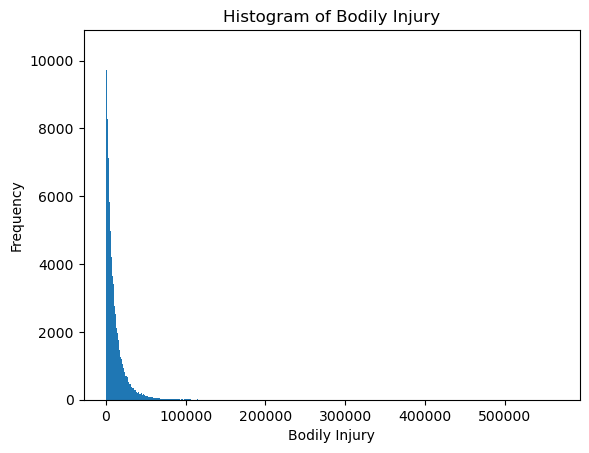

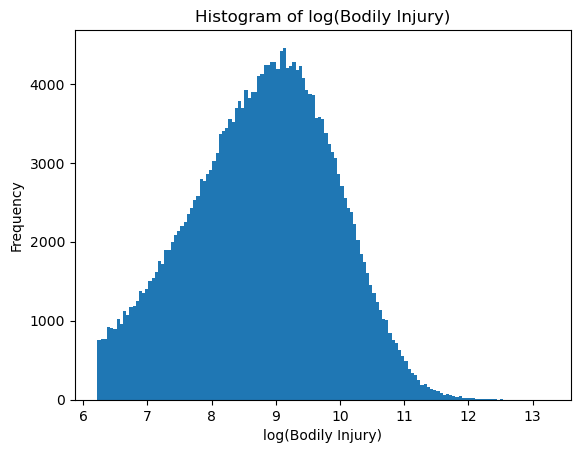

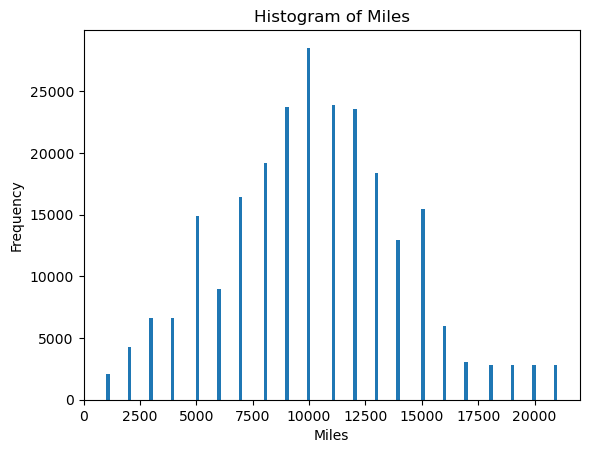

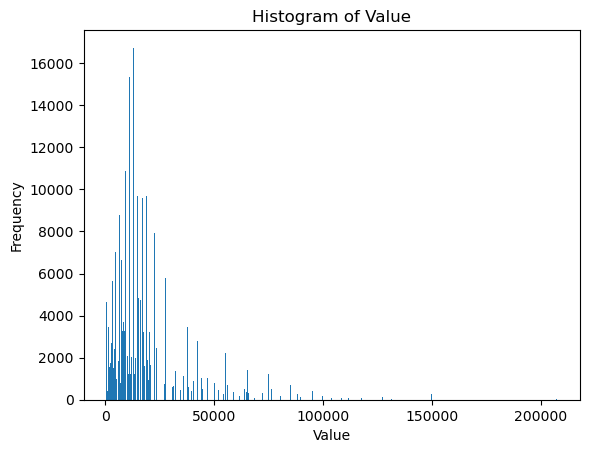

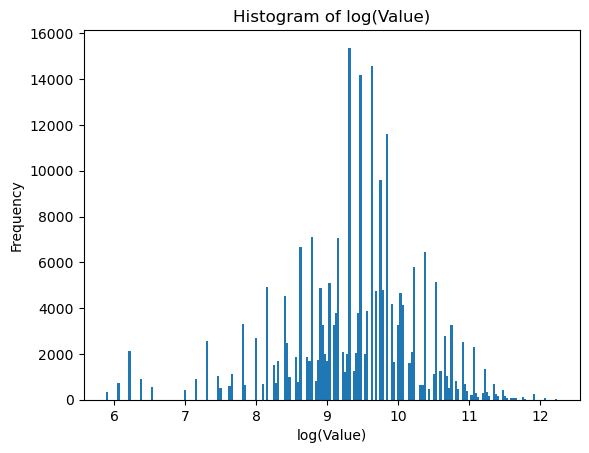

In [12]:
# Create histograms of univariate variables where the distribution may be of interest.
# Histogram for BodilyInjury
plt.hist(BI['BodilyInjury'], bins='auto')
plt.title('Histogram of Bodily Injury')
plt.xlabel('Bodily Injury')
plt.ylabel('Frequency')
plt.show()

# Histogram for log(BodilyInjury)
plt.hist(np.log(BI['BodilyInjury']), bins='auto')
plt.title('Histogram of log(Bodily Injury)')
plt.xlabel('log(Bodily Injury)')
plt.ylabel('Frequency')
plt.show()

# Histogram for Miles
plt.hist(BI['Miles'], bins='auto')
plt.title('Histogram of Miles')
plt.xlabel('Miles')
plt.ylabel('Frequency')
plt.show()

# Histogram for Value
plt.hist(BI['Value'], bins='auto')
plt.title('Histogram of Value')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

# Histogram for log(Value)
plt.hist(np.log(BI['Value']), bins='auto')
plt.title('Histogram of log(Value)')
plt.xlabel('log(Value)')
plt.ylabel('Frequency')
plt.show()

In [13]:
# The remaining numeric variables have defined ranges and don’t require any adjustments. 
# It seems that applying log transformations to BodilyInjury and Value will be useful, so they will be added to the data frame.
BI['lnTBI'] = np.log(BI['BodilyInjury'])
BI['lnValue'] = np.log(BI['Value'])
print(BI.describe())

                Year            Age          Miles     YearsOwned  \
count  245902.000000  245902.000000  245902.000000  245902.000000   
mean     2019.000000      48.287993   10238.436450       2.184443   
std         1.414219      14.564608    4045.711573       2.501568   
min      2017.000000      17.000000    1000.000000       0.000000   
25%      2018.000000      37.000000    8000.000000       0.000000   
50%      2019.000000      49.000000   10000.000000       1.000000   
75%      2020.000000      59.000000   13000.000000       3.000000   
max      2021.000000      80.000000   21000.000000      12.000000   

              CarAge          Value   BodilyInjury        Drivers  \
count  245902.000000  245902.000000  245902.000000  245902.000000   
mean        6.188624   17377.136140   11483.285508       1.649340   
std         4.197879   16573.573622   14147.326053       0.811068   
min         0.000000     361.000000     502.000000       1.000000   
25%         3.000000    7500.0000

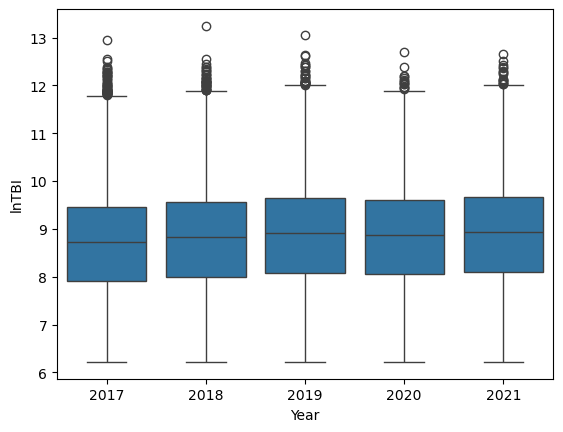

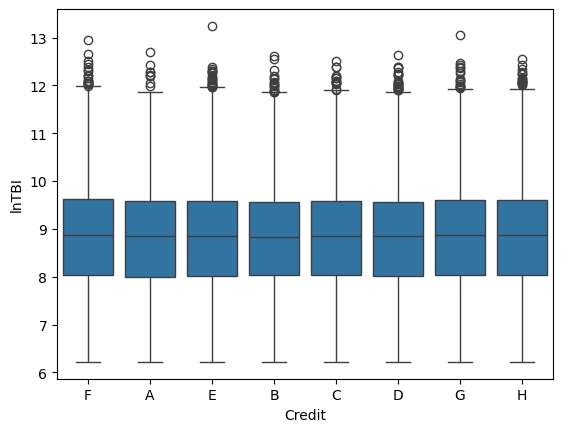

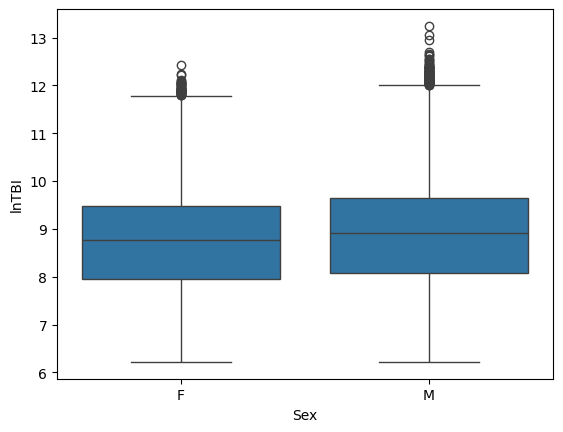

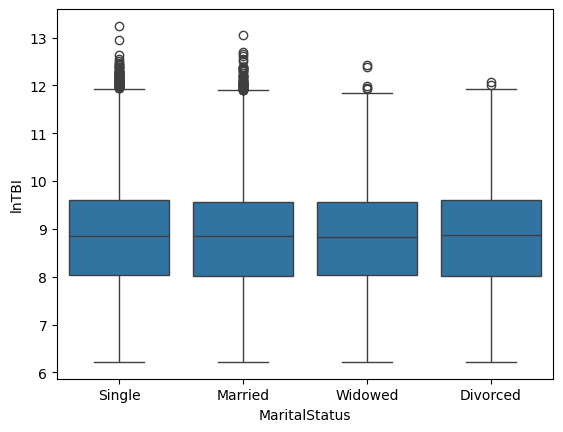

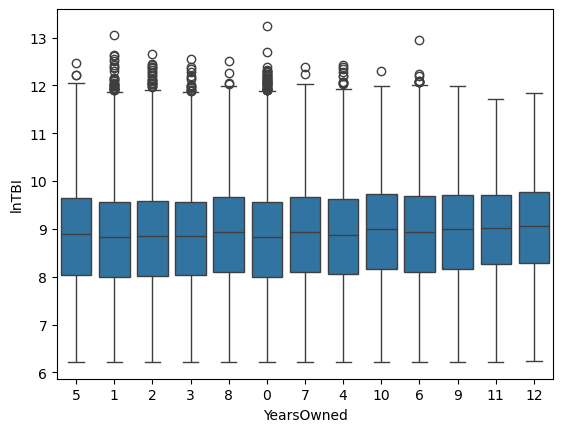

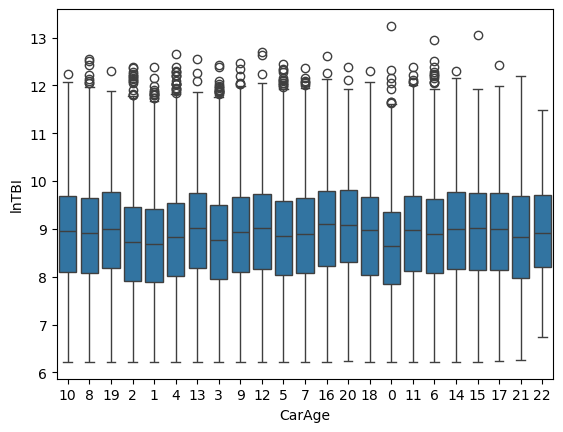

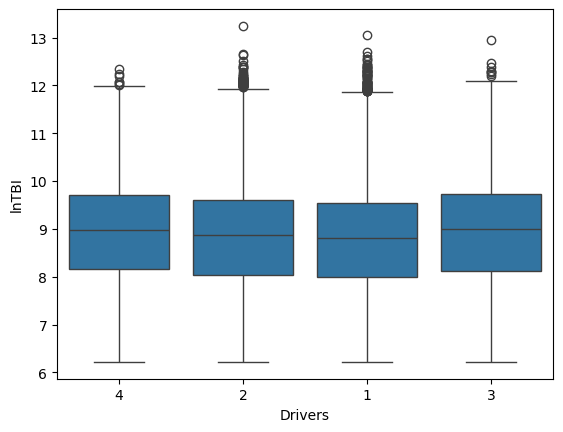

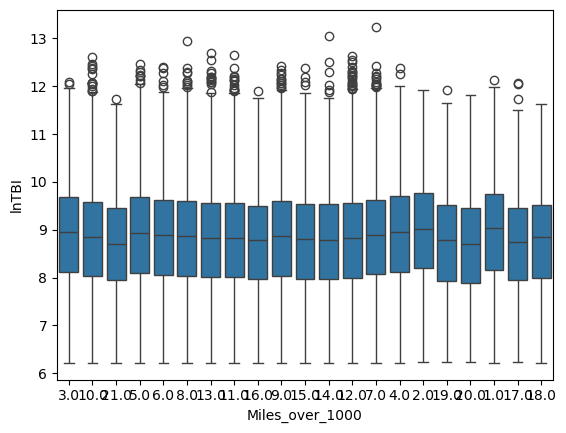

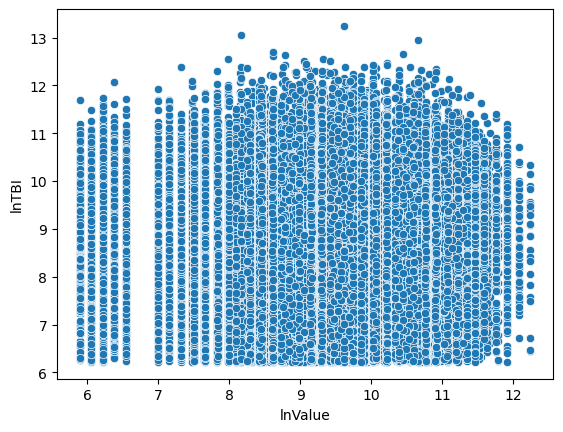

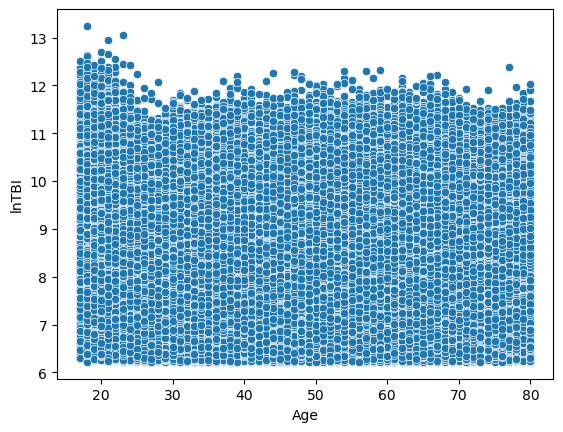

In [14]:
# TASK 2: EXPLORE RELATIONSHIPS OF PREDICTORS TO BODILYINJURY
# The following set of plots examines the relationship between the variables and the target. It appears that Miles is rounded to the nearest thousand, 
# resulting in a limited number of values. 
# Therefore, a box plot might be more effective in this case.

# Boxplot: Year vs lnTBI
sns.boxplot(data=BI, x=BI['Year'].astype(str), y='lnTBI')
plt.show()

# Boxplot: Credit vs lnTBI
sns.boxplot(data=BI, x='Credit', y='lnTBI')
plt.show()

# Boxplot: Sex vs lnTBI
sns.boxplot(data=BI, x='Sex', y='lnTBI')
plt.show()

# Boxplot: MaritalStatus vs lnTBI
sns.boxplot(data=BI, x='MaritalStatus', y='lnTBI')
plt.show()

# Boxplot: YearsOwned vs lnTBI
sns.boxplot(data=BI, x=BI['YearsOwned'].astype(str), y='lnTBI')
plt.show()

# Boxplot: CarAge vs lnTBI
sns.boxplot(data=BI, x=BI['CarAge'].astype(str), y='lnTBI')
plt.show()

# Boxplot: Drivers vs lnTBI
sns.boxplot(data=BI, x=BI['Drivers'].astype(str), y='lnTBI')
plt.show()

# Boxplot: Miles / 1000 vs lnTBI
BI['Miles_over_1000'] = BI['Miles'] / 1000
sns.boxplot(data=BI, x=BI['Miles_over_1000'].astype(str), y='lnTBI')
plt.show()

# Scatterplot: lnValue vs lnTBI
sns.scatterplot(data=BI, x='lnValue', y='lnTBI')
plt.show()

# Scatterplot: Age vs lnTBI
sns.scatterplot(data=BI, x='Age', y='lnTBI')
plt.show()

In [15]:
# The box plots show minimal impact for each variable. The scatter plots are so dense that they don’t provide much insight. 
# An alternative, non-graphical approach would be to calculate the average cost for each factor level or, in the case of the scatter plots, by bin. 

# Group by Year
year_group = BI.groupby('Year').agg(
    mean=('BodilyInjury', 'mean'),
    n=('BodilyInjury', 'size')
)

# Group by Credit
credit_group = BI.groupby('Credit').agg(
    mean=('BodilyInjury', 'mean'),
    n=('BodilyInjury', 'size')
)

# Group by Sex
sex_group = BI.groupby('Sex').agg(
    mean=('BodilyInjury', 'mean'),
    n=('BodilyInjury', 'size')
)

# Group by MaritalStatus
marital_status_group = BI.groupby('MaritalStatus').agg(
    mean=('BodilyInjury', 'mean'),
    n=('BodilyInjury', 'size')
)

# Group by YearsOwned
years_owned_group = BI.groupby('YearsOwned').agg(
    mean=('BodilyInjury', 'mean'),
    n=('BodilyInjury', 'size')
)

# Group by CarAge
car_age_group = BI.groupby('CarAge').agg(
    mean=('BodilyInjury', 'mean'),
    n=('BodilyInjury', 'size')
)

# Group by Drivers
drivers_group = BI.groupby('Drivers').agg(
    mean=('BodilyInjury', 'mean'),
    n=('BodilyInjury', 'size')
)

# Group by Miles / 1000
miles_group = BI.groupby(BI['Miles'] / 1000).agg(
    mean=('BodilyInjury', 'mean'),
    n=('BodilyInjury', 'size')
)

In [16]:
# Bin the other two variables
BI['ValueCut'] = pd.cut(BI['lnValue'], 10)
BI['AgeCut'] = pd.cut(BI['Age'], 10)
value_group = BI.groupby('ValueCut').agg(mean=('BodilyInjury', 'mean'), n=('BodilyInjury', 'size'))
age_group = BI.groupby('AgeCut').agg(mean=('BodilyInjury', 'mean'), n=('BodilyInjury', 'size'))
BI.drop(['ValueCut', 'AgeCut'], axis=1, inplace=True)

C:\Users\cedea\AppData\Local\Temp\ipykernel_215088\774188259.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  value_group = BI.groupby('ValueCut').agg(mean=('BodilyInjury', 'mean'), n=('BodilyInjury', 'size'))
C:\Users\cedea\AppData\Local\Temp\ipykernel_215088\774188259.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_group = BI.groupby('AgeCut').agg(mean=('BodilyInjury', 'mean'), n=('BodilyInjury', 'size'))


    Age          mean
0    17  29982.340190
1    18  32257.854467
2    19  26935.399633
3    20  24607.414776
4    21  23464.423931
..  ...           ...
59   76  11874.620047
60   77  12111.350222
61   78  11184.740088
62   79  12602.842152
63   80  11650.473039

[64 rows x 2 columns]


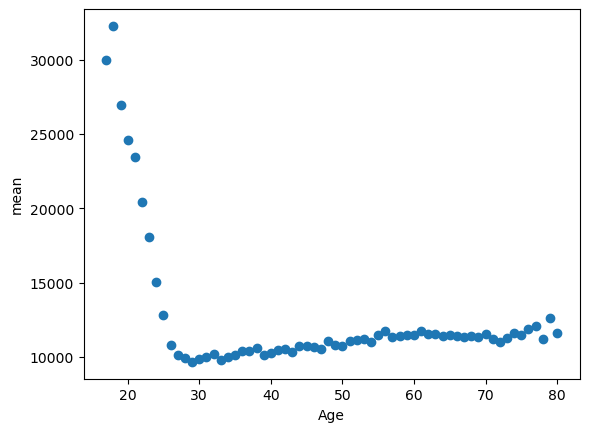

In [17]:
# These tables provide more meaningful insights.
# There’s an upward trend by Year, so we will retain this variable.
# Credit score shows an increasing trend, though it’s not perfect. Using it as a factor may result in lower predicted values for those with poorer credit. 
# To address this, we’ll convert it to numeric values ranging from 1 to 8, which will ensure a consistent increase.
# Males have a higher mean, so we will keep this variable.
# Marital status can influence costs by up to $300, so we will retain this variable.
# Costs rise with the number of years owned, so we will keep this variable.
# Costs also increase with car age, so we will retain this variable.
# Costs grow with the number of drivers, so we will keep this variable.
# Costs decrease with miles driven, so we will keep this variable.
# No clear pattern is seen with vehicle value, so we will drop this variable.
# The first age band shows a high value, followed by a drop and then a steady increase. The next plot shows the means for each individual age group.
AgeMeans = BI.groupby('Age').agg(mean=('BodilyInjury', 'mean')).reset_index()
print(AgeMeans)

plt.scatter(AgeMeans['Age'], AgeMeans['mean'])
plt.xlabel('Age')
plt.ylabel('mean')
plt.show()

In [ ]:
# It appears that the effect decreases linearly until age 27, then increases linearly after that. 
# While a decision tree can capture non-linear relationships, a GLM cannot. 
# To address this, we can create two new variables: AgeLow = Age for those under 27, or 27 otherwise, and AgeHigh = Age for those over 27, or 27 otherwise.

In [18]:
# Make the necessary changes (numerical values for Credit, remove Value, and create the new Age variables).
# We are now ready to proceed with building the models.

# Remove 'Value' and 'lnValue' columns
BI.drop(['Value', 'lnValue'], axis=1, inplace=True)

# Create 'AgeLow' and 'AgeHigh' variables
BI['AgeLow'] = BI['Age'].apply(lambda x: x if x < 27 else 27)
BI['AgeHigh'] = BI['Age'].apply(lambda x: x if x > 27 else 27)

# Perform linear regression
X = BI[['AgeLow', 'AgeHigh']]
X = sm.add_constant(X)
y = BI['BodilyInjury']
model = sm.OLS(y, X).fit()
print(model.summary())  # See if the recoding works by matching estimated slopes to the graph made earlier. Looks good.

# Convert 'Credit' to numeric
BI['CreditNum'] = BI['Credit'].astype('category').cat.codes + 1  # Sets A = 1, B = 2, etc.

# Remove 'Credit' column
BI.drop('Credit', axis=1, inplace=True)

# Summary of BI
print(BI.describe())

                            OLS Regression Results                            
Dep. Variable:           BodilyInjury   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     4519.
Date:                Tue, 28 Jan 2025   Prob (F-statistic):               0.00
Time:                        05:53:14   Log-Likelihood:            -2.6946e+06
No. Observations:              245902   AIC:                         5.389e+06
Df Residuals:                  245899   BIC:                         5.389e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       6.619e+04    576.099    114.886      0.0

In [19]:
# Define 'Sex' as numeric
sex_category_mapping = {'F': 0, 'M': 1}
BI['Sex'] = BI['Sex'].map(sex_category_mapping)

In [20]:
# Define 'MaritalStatus' as numeric
marital_category_mapping = {'Single': 0, 'Divorced': 1, 'Married': 2, 'Widowed': 3}
BI['MaritalStatus'] = BI['MaritalStatus'].map(marital_category_mapping)

In [ ]:
# TASK 3: SELECT AN INITIAL MODEL FORM

# There are two main objectives. The first is selecting important features. 
# Decision trees automatically handle this by excluding features that are never used for splits. 
# Simpler trees tend to use fewer features. For GLMs, feature selection can be achieved through methods like hypothesis tests or regularization.

# The second goal is making accurate predictions. 
# A challenge arises with trees when many numeric predictors are used (even though many may have a limited number of values). 
# If there’s a true linear relationship, it may take numerous splits to partition the feature space and allow each interval to have an effect. 
# This could result in a deeper tree, which may increase the risk of overfitting.

# Although not explicitly mentioned, interpreting and explaining the model is also important. 
# Decision trees are easy to explain, but a deep tree can complicate drawing conclusions. 
# GLMs may be a bit more difficult to understand if unfamiliar, but interpreting their coefficients is straightforward.

# Both models are easy to implement, so that is not an issue.

# Based on the above, a GLM is recommended. It is likely to make better predictions, allows for feature selection, and is easy to explain.

In [21]:
# TASK 4: FIT THE BEST MODEL
# After selecting a GLM, the first step is to choose the appropriate distributions and link functions. We will explore four combinations:

# Normal distribution with an identity link. This is standard regression and can serve as a useful benchmark.
# Normal distribution with a log link. This guarantees positive predictions, though the distribution might not be accurate.
# Gamma distribution with a log link. This accounts for the skewness in the target distribution.
# Predict the log of the target using a normal distribution and identity link. Since logarithms can yield negative values, a model that predicts negative values is acceptable.
# There is no one-size-fits-all method for choosing model forms and performing variable selection. The approach we will follow mirrors the one used in Section 1. Fit the model, apply the likelihood ratio test to determine if a feature should be removed, and repeat until no further removals are needed. Then, evaluate the model using the test set and perform diagnostic checks. (Note that the glmnet package cannot handle regularized regression for all four models.)

# Before evaluating each model, the dataset will be split into training, testing, and holdout sets.
from sklearn.model_selection import train_test_split

# Set seed for reproducibility
np.random.seed(1000)

# Partition the data into training (70%) and testing (30%) sets
train_indices = train_test_split(
    BI.index,
    train_size=0.7,
    random_state=1000
)[0]
BI_train = BI.loc[train_indices]
BI_test = BI.drop(train_indices)

# Further partition the testing set into test (2/3) and hold (1/3)
test_indices = train_test_split(
    BI_test.index,
    train_size=2/3,
    random_state=1000
)[0]
BI_hold = BI_test.drop(test_indices)
BI_test = BI_test.loc[test_indices]

# Remove temporary variables
del train_indices
del test_indices

In [22]:
# Model 1 - Normal identity
# For this model, BodilyInjury is the target and all variables can be used except Age and lnTBI.
import statsmodels.api as sm
import pandas as pd
from scipy.stats import chi2

# Fit the linear model
glm1 = sm.OLS.from_formula('BodilyInjury ~ ' + ' + '.join([col for col in BI_train.columns if col not in ['lnTBI', 'Age', 'BodilyInjury']]), data=BI_train).fit()

# Perform likelihood ratio tests for each predictor
d = pd.DataFrame(columns=['Df', 'Deviance', 'AIC', 'LRT', 'Pr(>Chi)'])
base_deviance = np.sum(glm1.resid ** 2)
base_df = glm1.df_resid

for predictor in glm1.model.exog_names[1:]:  # Skip intercept
    # Fit model without the current predictor
    reduced_formula = 'BodilyInjury ~ ' + ' + '.join([col for col in glm1.model.exog_names[1:] if col != predictor])
    reduced_model = sm.OLS.from_formula(reduced_formula, data=BI_train).fit()
    
    # Calculate statistics
    reduced_deviance = np.sum(reduced_model.resid ** 2)
    df_diff = reduced_model.df_resid - glm1.df_resid
    lrt_stat = len(BI_train) * (np.log(reduced_deviance) - np.log(base_deviance))
    p_value = chi2.sf(lrt_stat, df_diff)
    
    # Add to results DataFrame
    d.loc[predictor] = [df_diff, reduced_deviance, reduced_model.aic, lrt_stat, p_value]

# Display results
print(d)

# Find the row with maximum p-value
max_p_value_row = d.iloc[d['Pr(>Chi)'].argmax()]
print("\nRow with maximum p-value:")
print(max_p_value_row)

                  Df      Deviance           AIC           LRT       Pr(>Chi)
Year             1.0  3.279950e+13  3.770257e+06  5.707990e+02  3.762874e-126
Sex              1.0  3.285046e+13  3.770524e+06  8.380031e+02  2.949428e-184
MaritalStatus    1.0  3.269342e+13  3.769699e+06  1.316674e+01   2.849613e-04
Miles            0.0  3.269092e+13  3.769688e+06  0.000000e+00            NaN
YearsOwned       1.0  3.269092e+13  3.769686e+06  1.845056e-02   8.919534e-01
CarAge           1.0  3.280846e+13  3.770304e+06  6.177978e+02  2.252792e-136
Drivers          1.0  3.276893e+13  3.770097e+06  4.102931e+02   3.164689e-91
Miles_over_1000  0.0  3.269092e+13  3.769688e+06  6.115322e-10            NaN
AgeLow           1.0  3.375762e+13  3.775213e+06  5.526915e+03   0.000000e+00
AgeHigh          1.0  3.271345e+13  3.769805e+06  1.186175e+02   1.270012e-27
CreditNum        1.0  3.269162e+13  3.769690e+06  3.719355e+00   5.378515e-02

Row with maximum p-value:
Df          1.000000e+00
Deviance    

In [23]:
# Drop YearsOwned and repeat
# Fit the linear model
glm1 = sm.OLS.from_formula('BodilyInjury ~ ' + ' + '.join([col for col in BI_train.columns if col not in ['lnTBI', 'Age', 'BodilyInjury', 'YearsOwned']]), data=BI_train).fit()

# Perform likelihood ratio tests for each predictor
d = pd.DataFrame(columns=['Df', 'Deviance', 'AIC', 'LRT', 'Pr(>Chi)'])
base_deviance = np.sum(glm1.resid ** 2)
base_df = glm1.df_resid

for predictor in glm1.model.exog_names[1:]:  # Skip intercept
    # Fit model without the current predictor
    reduced_formula = 'BodilyInjury ~ ' + ' + '.join([col for col in glm1.model.exog_names[1:] if col != predictor])
    reduced_model = sm.OLS.from_formula(reduced_formula, data=BI_train).fit()
    
    # Calculate statistics
    reduced_deviance = np.sum(reduced_model.resid ** 2)
    df_diff = reduced_model.df_resid - glm1.df_resid
    lrt_stat = len(BI_train) * (np.log(reduced_deviance) - np.log(base_deviance))
    p_value = chi2.sf(lrt_stat, df_diff)
    
    # Add to results DataFrame
    d.loc[predictor] = [df_diff, reduced_deviance, reduced_model.aic, lrt_stat, p_value]

# Display results
print(d)

# Find the row with maximum p-value
max_p_value_row = d.iloc[d['Pr(>Chi)'].argmax()]
print("\nRow with maximum p-value:")
print(max_p_value_row)

                  Df      Deviance           AIC          LRT       Pr(>Chi)
Year             1.0  3.280118e+13  3.770264e+06   579.578978  4.630859e-128
Sex              1.0  3.285047e+13  3.770522e+06   838.048062  2.883796e-184
MaritalStatus    1.0  3.269342e+13  3.769697e+06    13.160859   2.858579e-04
Miles            0.0  3.269092e+13  3.769686e+06     0.000000            NaN
CarAge           1.0  3.283993e+13  3.770467e+06   782.825294  2.925513e-172
Drivers          1.0  3.276893e+13  3.770095e+06   410.275765   3.192270e-91
Miles_over_1000  0.0  3.269092e+13  3.769686e+06     0.000000            NaN
AgeLow           1.0  3.375762e+13  3.775211e+06  5526.913128   0.000000e+00
AgeHigh          1.0  3.271346e+13  3.769803e+06   118.627079   1.263916e-27
CreditNum        1.0  3.269163e+13  3.769688e+06     3.721395   5.371947e-02

Row with maximum p-value:
Df          1.000000e+00
Deviance    3.269163e+13
AIC         3.769688e+06
LRT         3.721395e+00
Pr(>Chi)    5.371947e-02
N

In [24]:
# Drop CreditNum and repeat
# Fit the linear model
glm1 = sm.OLS.from_formula('BodilyInjury ~ ' + ' + '.join([col for col in BI_train.columns if col not in ['lnTBI', 'Age', 'BodilyInjury', 'YearsOwned','CreditNum']]), data=BI_train).fit()

# Perform likelihood ratio tests for each predictor
d = pd.DataFrame(columns=['Df', 'Deviance', 'AIC', 'LRT', 'Pr(>Chi)'])
base_deviance = np.sum(glm1.resid ** 2)
base_df = glm1.df_resid

for predictor in glm1.model.exog_names[1:]:  # Skip intercept
    # Fit model without the current predictor
    reduced_formula = 'BodilyInjury ~ ' + ' + '.join([col for col in glm1.model.exog_names[1:] if col != predictor])
    reduced_model = sm.OLS.from_formula(reduced_formula, data=BI_train).fit()
    
    # Calculate statistics
    reduced_deviance = np.sum(reduced_model.resid ** 2)
    df_diff = reduced_model.df_resid - glm1.df_resid
    lrt_stat = len(BI_train) * (np.log(reduced_deviance) - np.log(base_deviance))
    p_value = chi2.sf(lrt_stat, df_diff)
    
    # Add to results DataFrame
    d.loc[predictor] = [df_diff, reduced_deviance, reduced_model.aic, lrt_stat, p_value]

# Display results
print(d)

# Find the row with maximum p-value
max_p_value_row = d.iloc[d['Pr(>Chi)'].argmax()]
print("\nRow with maximum p-value:")
print(max_p_value_row)

                  Df      Deviance           AIC          LRT       Pr(>Chi)
Year             1.0  3.280196e+13  3.770266e+06   579.946863  3.851581e-128
Sex              1.0  3.285133e+13  3.770525e+06   838.817089  1.962338e-184
MaritalStatus    1.0  3.269414e+13  3.769699e+06    13.215641   2.776225e-04
Miles            0.0  3.269163e+13  3.769688e+06     0.000000            NaN
CarAge           1.0  3.284155e+13  3.770474e+06   787.573157  2.715856e-173
Drivers          1.0  3.276971e+13  3.770097e+06   410.649301   2.647223e-91
Miles_over_1000  0.0  3.269163e+13  3.769688e+06     0.000000            NaN
AgeLow           1.0  3.376173e+13  3.775230e+06  5544.136301   0.000000e+00
AgeHigh          1.0  3.271391e+13  3.769803e+06   117.267951   2.507904e-27

Row with maximum p-value:
Df          1.000000e+00
Deviance    3.269414e+13
AIC         3.769699e+06
LRT         1.321564e+01
Pr(>Chi)    2.776225e-04
Name: MaritalStatus, dtype: float64


In [ ]:
# All features are significant, so we keep this as Model 1.

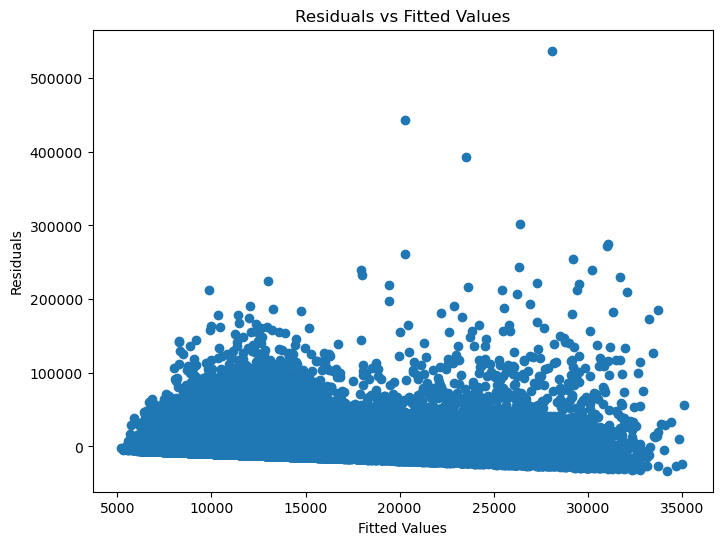

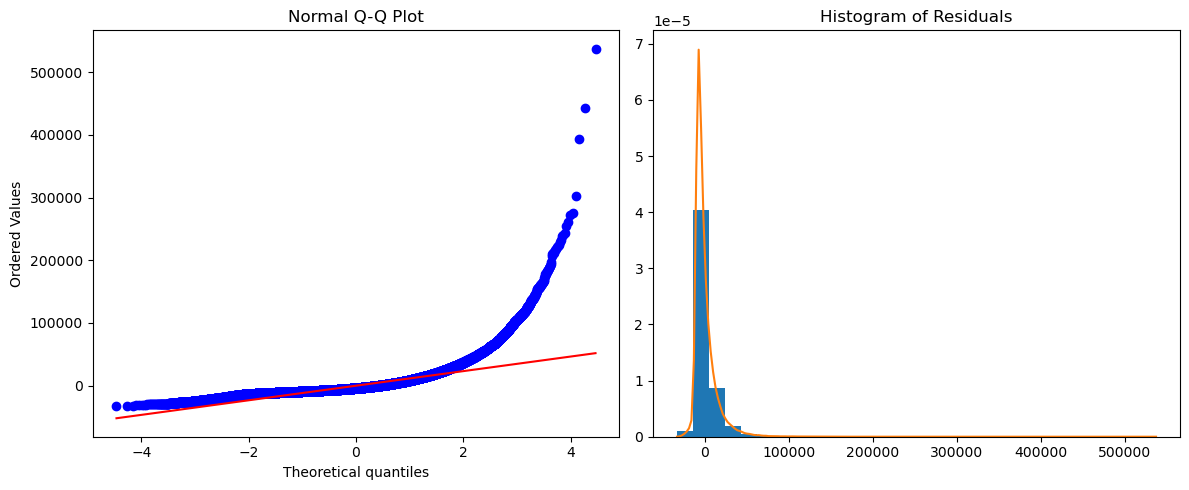

In [30]:
# Make predictions on test data
predict_test = glm1.predict(BI_test, "response")
rmse = np.sqrt(np.sum((predict_test - BI_test['BodilyInjury'])**2) / len(BI_test))

# Create residuals vs fitted plot
plt.figure(figsize=(8, 6))
plt.scatter(glm1.fittedvalues, glm1.resid)
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values')
plt.show()

# Create dataframe for plotting
plot_data = pd.DataFrame({
    'residuals': glm1.resid,
    'fitted': glm1.fittedvalues
})

# Create subplot figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Q-Q plot
stats.probplot(plot_data['residuals'], dist="norm", plot=ax1)
ax1.set_title('Normal Q-Q Plot')

# Histogram of residuals
ax2.hist(plot_data['residuals'], bins=30, density=True)
ax2.set_title('Histogram of Residuals')

# Add a density curve to the histogram
density = stats.gaussian_kde(plot_data['residuals'])
xs = np.linspace(plot_data['residuals'].min(), plot_data['residuals'].max(), 200)
ax2.plot(xs, density(xs))

plt.tight_layout()
plt.show()

In [224]:
rmse

13874.831372988689

In [303]:
# Model 2 - Normal log
# We target BodilyInjury and use all variables except Age and lnTBI.
# Fit GLM model
glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + YearsOwned + CarAge + Drivers + AgeLow + AgeHigh + CreditNum',
    data=BI_train,
    family=sm.families.Gaussian(sm.families.links.log())
).fit()

# Function to perform likelihood ratio test for each predictor
def drop1_lrt(model, data):
    base_ll = model.llf
    results = []
    predictors = data.drop(['BodilyInjury', 'lnTBI', 'Age'], axis=1).columns
    
    for predictor in predictors:
        # Fit model without the predictor
        reduced_data = data.drop([predictor, 'lnTBI', 'Age'], axis=1)
        reduced_model = sm.GLM(reduced_data['BodilyInjury'], 
                             sm.add_constant(reduced_data.drop('BodilyInjury', axis=1)), 
                             family=sm.families.Gaussian(sm.families.links.log())).fit()
        
        # Calculate LRT statistic
        lrt_stat = 2 * (base_ll - reduced_model.llf)
        df = 1  # Degrees of freedom is 1 for single predictor
        p_value = chi2.sf(lrt_stat, df)
        
        results.append({
            'Predictor': predictor,
            'Df': df,
            'LRT Stat': lrt_stat,
            'Pr(>Chi)': p_value
        })
    
    return pd.DataFrame(results)

# Perform drop1 analysis
d = drop1_lrt(glm2, BI_train)
print(d)

C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: Futu

       Predictor  Df     LRT Stat       Pr(>Chi)
0           Year   1   651.645106  9.802429e-144
1            Sex   1  1304.011450  1.518722e-285
2  MaritalStatus   1     8.704586   3.174106e-03
3          Miles   1    85.400654   2.436400e-20
4     YearsOwned   1     0.134003   7.143168e-01
5         CarAge   1   627.037452  2.203691e-138
6        Drivers   1   471.350164  1.629161e-104
7         AgeLow   1  6080.050548   0.000000e+00
8        AgeHigh   1    66.817346   2.978656e-16
9      CreditNum   1     7.567353   5.943500e-03


In [304]:
# Drop YearsOwned and repeat
# Fit GLM model
glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + CarAge + Drivers + AgeLow + AgeHigh + CreditNum',
    data=BI_train,
    family=sm.families.Gaussian(sm.families.links.log())
).fit()

# Function to perform likelihood ratio test for each predictor
def drop1_lrt(model, data):
    base_ll = model.llf
    results = []
    predictors = data.drop(['BodilyInjury', 'lnTBI', 'Age', 'YearsOwned'], axis=1).columns
    
    for predictor in predictors:
        # Fit model without the predictor
        reduced_data = data.drop([predictor, 'lnTBI', 'Age', 'YearsOwned'], axis=1)
        reduced_model = sm.GLM(reduced_data['BodilyInjury'], 
                             sm.add_constant(reduced_data.drop('BodilyInjury', axis=1)), 
                             family=sm.families.Gaussian(sm.families.links.log())).fit()
        
        # Calculate LRT statistic
        lrt_stat = 2 * (base_ll - reduced_model.llf)
        df = 1  # Degrees of freedom is 1 for single predictor
        p_value = chi2.sf(lrt_stat, df)
        
        results.append({
            'Predictor': predictor,
            'Df': df,
            'LRT Stat': lrt_stat,
            'Pr(>Chi)': p_value
        })
    
    return pd.DataFrame(results)

# Perform drop1 analysis
d = drop1_lrt(glm2, BI_train)
print(d)

C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: Futu

       Predictor  Df     LRT Stat       Pr(>Chi)
0           Year   1   661.508936  7.017425e-146
1            Sex   1  1303.885555  1.617473e-285
2  MaritalStatus   1     8.710655   3.163556e-03
3          Miles   1    85.289976   2.576661e-20
4         CarAge   1   796.991750  2.432822e-175
5        Drivers   1   471.575026  1.455569e-104
6         AgeLow   1  6080.219516   0.000000e+00
7        AgeHigh   1    66.847426   2.933551e-16
8      CreditNum   1     7.560970   5.964587e-03


In [32]:
# Drop CreditNum and repeat
# Fit GLM model
glm2 = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + YearsOwned + CarAge + Drivers + AgeLow + AgeHigh',
    data=BI_train,
    family=sm.families.Gaussian(sm.families.links.log())
).fit()

# Function to perform likelihood ratio test for each predictor
def drop1_lrt(model, data):
    base_ll = model.llf
    results = []
    predictors = data.drop(['BodilyInjury', 'lnTBI', 'Age', 'YearsOwned', 'CreditNum'], axis=1).columns
    
    for predictor in predictors:
        # Fit model without the predictor
        reduced_data = data.drop([predictor, 'lnTBI', 'Age', 'YearsOwned', 'CreditNum'], axis=1)
        reduced_model = sm.GLM(reduced_data['BodilyInjury'], 
                             sm.add_constant(reduced_data.drop('BodilyInjury', axis=1)), 
                             family=sm.families.Gaussian(sm.families.links.log())).fit()
        
        # Calculate LRT statistic
        lrt_stat = 2 * (base_ll - reduced_model.llf)
        df = 1  # Degrees of freedom is 1 for single predictor
        p_value = chi2.sf(lrt_stat, df)
        
        results.append({
            'Predictor': predictor,
            'Df': df,
            'LRT Stat': lrt_stat,
            'Pr(>Chi)': p_value
        })
    
    return pd.DataFrame(results)

# Perform drop1 analysis
d = drop1_lrt(glm2, BI_train)
print(d)

C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(
C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: Futu

         Predictor  Df     LRT Stat       Pr(>Chi)
0             Year   1   662.777772  3.717395e-146
1              Sex   1  1304.873914  9.864009e-286
2    MaritalStatus   1     8.952207   2.771345e-03
3            Miles   1     0.127620   7.209121e-01
4           CarAge   1   805.315144  3.771011e-177
5          Drivers   1   470.940312  2.000555e-104
6  Miles_over_1000   1     0.127620   7.209121e-01
7           AgeLow   1  6098.827132   0.000000e+00
8          AgeHigh   1    65.439899   5.991353e-16


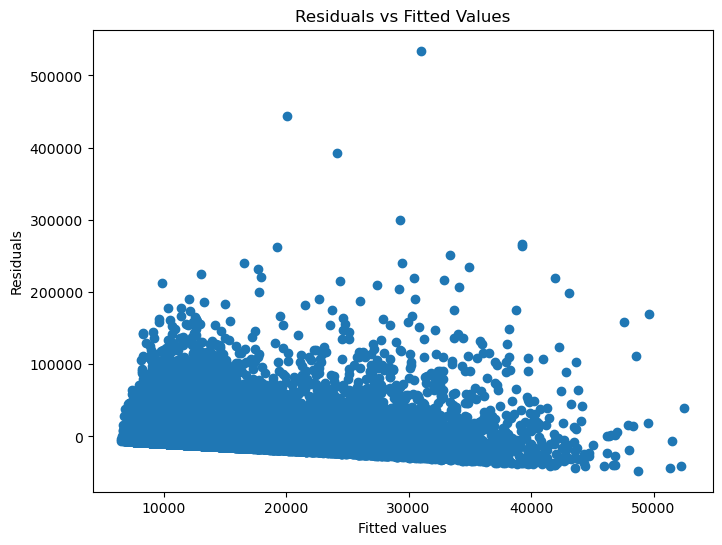

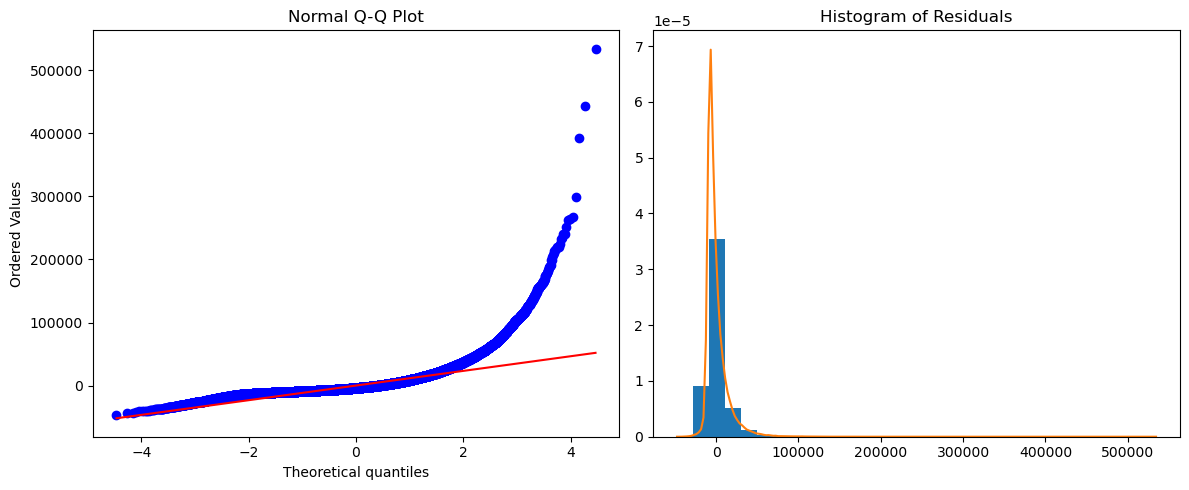

In [35]:
# Review the Diagnostics
# Make predictions on test data
predict_test = glm2.predict(BI_test)
rmse = np.sqrt(np.sum((predict_test - BI_test['BodilyInjury'])**2) / len(BI_test))

# Create residuals vs fitted plot
plt.figure(figsize=(8, 6))
plt.scatter(glm2.fittedvalues, glm2.resid_response)
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values')
plt.show()

# Create dataframe for plotting
plot_data = pd.DataFrame({
    'residuals': glm2.resid_response,
    'fitted': glm2.fittedvalues
})

# Create subplot figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Q-Q plot
stats.probplot(plot_data['residuals'], dist="norm", plot=ax1)
ax1.set_title('Normal Q-Q Plot')

# Histogram of residuals
ax2.hist(plot_data['residuals'], bins=30, density=True)
ax2.set_title('Histogram of Residuals')

# Add a density curve to the histogram
density = stats.gaussian_kde(plot_data['residuals'])
xs = np.linspace(plot_data['residuals'].min(), plot_data['residuals'].max(), 200)
ax2.plot(xs, density(xs))

plt.tight_layout()
plt.show()

In [307]:
rmse

13845.828606846182

In [ ]:
# Still not good.

C:\Users\cedea\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  warnings.warn(


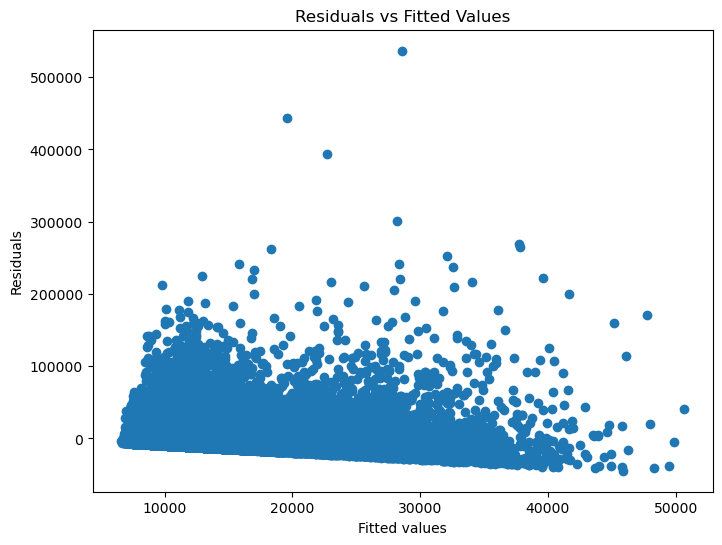

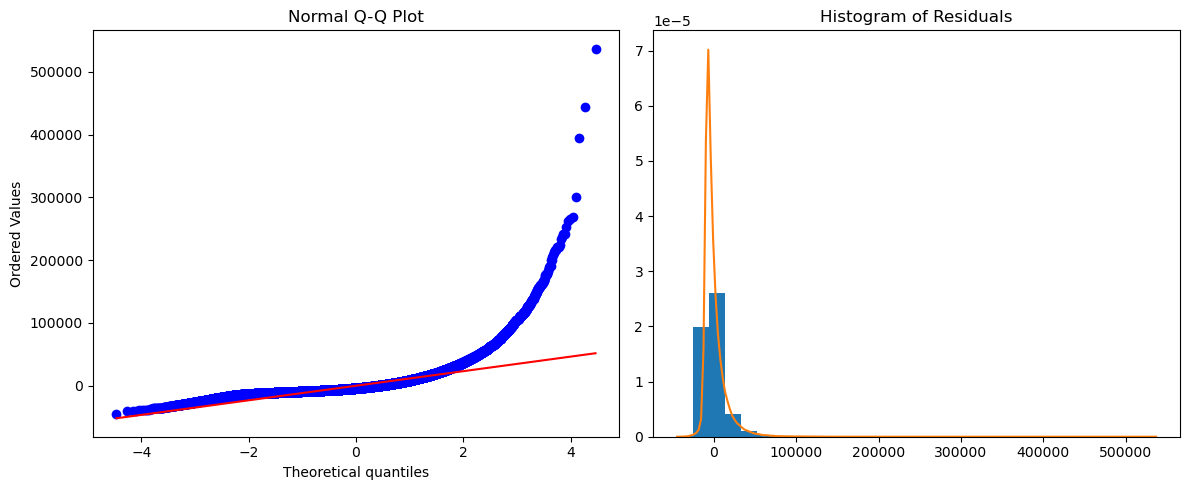

In [309]:
# Model 3A - Inverse Gaussian Log
# Fit inverse gaussian GLM with log link
glm3a = smf.glm(
    formula='BodilyInjury ~ Year + Sex + MaritalStatus + Miles + YearsOwned + CarAge + Drivers + AgeLow + AgeHigh',
    data=BI_train,
    family=sm.families.InverseGaussian(sm.families.links.log())
).fit()

predict_test = glm3a.predict(BI_test)
rmse = np.sqrt(np.sum((predict_test - BI_test['BodilyInjury'])**2) / len(BI_test))

# Create residuals vs fitted plot
plt.figure(figsize=(8, 6))
plt.scatter(glm3a.fittedvalues, glm3a.resid_response)
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values')
plt.show()

# Create dataframe for plotting
plot_data = pd.DataFrame({
    'residuals': glm3a.resid_response,
    'fitted': glm3a.fittedvalues
})

# Create subplot figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Q-Q plot
stats.probplot(plot_data['residuals'], dist="norm", plot=ax1)
ax1.set_title('Normal Q-Q Plot')

# Histogram of residuals
ax2.hist(plot_data['residuals'], bins=30, density=True)
ax2.set_title('Histogram of Residuals')

# Add a density curve to the histogram
density = stats.gaussian_kde(plot_data['residuals'])
xs = np.linspace(plot_data['residuals'].min(), plot_data['residuals'].max(), 200)
ax2.plot(xs, density(xs))

plt.tight_layout()
plt.show()

In [ ]:
# Slightly overcorrected, but is the best thus far.

In [310]:
rmse

13860.758123715106

In [316]:
# TASK 5: FIT THE OTHER MODEL
# Fit a tree.

from sklearn.tree import DecisionTreeRegressor
import numpy as np

# Create the decision tree regressor
# Remove specified columns from the feature set
X_test = BI_test.drop(['BodilyInjury', 'lnTBI', 'AgeHigh', 'AgeLow'], axis=1)
y_test = BI_test['BodilyInjury']

# Initialize and fit the tree
tree_bodily_injury = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)
tree_bodily_injury.fit(X_test, y_test)

DecisionTreeRegressor(max_depth=10, random_state=42)

In [317]:
# Make predictions and calculate RMSE
predictions_test = tree_bodily_injury.predict(X_test)
rmse = np.sqrt(np.mean((predictions_test - y_test) ** 2))
print(f"RMSE: {rmse}")

RMSE: 12817.458666385051
